# Basics of spin dynamics with `SpinLibrary.jl`

The Julia file `SpinLibrary.jl` builds the states and operators of one spin $S$ as plain vectors and matrices
of size $N = 2S+1$, and evolves states by exact diagonalisation.

| Section | What it does |
|---|---|
| 1. Setup | packages, the library, and a few small helper functions |
| 2. Tests | states, pulses and evolutions, compared with exact results |
| 3. Bloch sphere | how to draw a state on the sphere |
| 4. Dynamics | evolutions and pulse sequences: curves of the spin moments and snapshots on the sphere |

**Basis convention.** The basis vector number $k = 1, \dots, 2S+1$ (Julia counts from 1) is the Dicke state
$|S, m\rangle$ with $m = S + 1 - k$, i.e. from $m = +S$ down to $m = -S$: $|S,S\rangle = (1, 0, \dots, 0)$.

## 1. Setup

### 1.1 Packages
* **LinearAlgebra**, **Printf** (standard library): eigenvalues, scalar products, formatted printing.
* **CairoMakie** and **LaTeXStrings**: plots (also 3D) with $\LaTeX$ labels.
* **JLD2**: saving and loading Julia objects (`save_object`, `load_object`).

The packages are installed only if they are missing, so later runs are fast.

In [1]:
import Pkg
for pkg in ["CairoMakie", "LaTeXStrings", "JLD2"]
    Base.find_package(pkg) === nothing && Pkg.add(pkg)      # install only if missing
end

using LinearAlgebra                  # eigvals, eigvecs, dot, norm, diag
using Printf                         # @printf for aligned tables
using CairoMakie                     # plots
using LaTeXStrings                   # L"..." labels
using JLD2                           # save_object / load_object
CairoMakie.activate!(type = "png", px_per_unit = 2)   # sharp PNG images (light also for 3D surfaces)

### 1.2 The library
`include` runs the file, so all its functions become available here. The path is relative to this notebook.

In [2]:
include("../src_jul/SpinLibrary.jl")

evol_diag (generic function with 1 method)

### 1.3 Helper functions
The library provides states and operators; these few lines add what is used in every section:

* `expval(A, psi)` and `variance(A, psi)`: mean value and variance of an operator $A$ in the state $\psi$.
  The variance is computed as $\|(A - \langle A\rangle)\psi\|^2$: the mean is subtracted *before* squaring,
  so no large numbers cancel (unlike $\langle A^2\rangle - \langle A\rangle^2$) and the result is never negative.
* `print_spin(S, psi, name)`: norm, mean spin and variances, one axis per line.
* `pulse(A, alpha, psi)`: the rotation $e^{-i\alpha A}\psi$ about the axis of the spin operator $A$. It is the
  evolution under the "Hamiltonian" $A$ for a "time" $\alpha$, computed with the library's `diagonalisation` and `evolution`.

In [3]:
expval(A, psi) = real(dot(psi, A * psi))          # <psi|A|psi>  (dot conjugates its first argument)

function variance(A, psi)
    m = expval(A, psi)
    return norm(A * psi - m * psi)^2               # || (A - <A>) psi ||^2
end

function print_spin(S, psi, name = "state")
    println(name, " :  <psi|psi> = ", round(real(dot(psi, psi)), digits = 6))
    for (A, a) in ((Sx(S), "x"), (Sy(S), "y"), (Sz(S), "z"))
        println("    <S$a> = ", round(expval(A, psi), digits = 4), "\tVar(S$a) = ", round(variance(A, psi), digits = 4))
    end
end

pulse(A, alpha, psi) = evolution(diagonalisation(A)..., psi, alpha)   # exp(-i alpha A) psi

pulse (generic function with 1 method)

## 2. Tests

The same checks as for the C++/Python library, with the functions of `SpinLibrary.jl`.

### 2.1 Coherent states along the axes
A **coherent spin state** (CSS) is the spin fully polarised along one direction: the mean spin has length $S$
along that axis, and the variance in the two perpendicular directions is $S/2$ (the *standard quantum limit*).

| State | Library function |
|---|---|
| CSS along $+z$ | `init_Dickez(S, 1)`, the first basis vector $\lvert S, S\rangle$ |
| CSS along $\pm x$ | `init_cssX(S)`, `init_cssXm(S)` |
| CSS along any direction $(\theta, \varphi)$ | `init_css(S, theta, phi)` (see 2.2) |

**Expected:** $\langle S\rangle = \pm S$ along the axis, $\mathrm{Var} = S/2$ in the other two directions, $0$ along it.

In [4]:
S = 10                                                    # spin length: dimension N = 2S + 1 = 21

print_spin(S, init_Dickez(S, 1), "CSS+Z")
print_spin(S, init_cssXm(S), "CSS-X")
print_spin(S, init_css(S, pi/2, pi/2), "CSS+Y")          # theta = pi/2 (equator), phi = pi/2 (y axis)

CSS+Z :  <psi|psi> = 1.0
    <Sx> = 0.0	Var(Sx) = 5.0
    <Sy> = 0.0	Var(Sy) = 5.0
    <Sz> = 10.0	Var(Sz) = 0.0
CSS-X :  <psi|psi> = 1.0
    <Sx> = -10.0	Var(Sx) = 0.0
    <Sy> = 0.0	Var(Sy) = 5.0
    <Sz> = 0.0	Var(Sz) = 5.0
CSS+Y :  <psi|psi> = 1.0
    <Sx> = 0.0	Var(Sx) = 5.0
    <Sy> = 10.0	Var(Sy) = 0.0
    <Sz> = 0.0	Var(Sz) = 5.0


### 2.2 Coherent state along an arbitrary direction
`init_css(S, theta, phi)` polarises the spin along the unit vector
$\vec n = (\sin\theta\cos\varphi,\ \sin\theta\sin\varphi,\ \cos\theta)$, with the angles in radians.

**Expected:** $\langle \vec S\rangle = S\,\vec n$, printed below for comparison.

In [5]:
theta, phi = 0.7, 1.1
print_spin(S, init_css(S, theta, phi), "CSS(0.7, 1.1)")

n = S .* [sin(theta) * cos(phi), sin(theta) * sin(phi), cos(theta)]
@printf("Expected:  <Sx> = %.4f   <Sy> = %.4f   <Sz> = %.4f\n", n...)

CSS(0.7, 1.1) :  <psi|psi> = 1.0
    <Sx> = 2.9221	Var(Sx) = 4.5731
    <Sy> = 5.7413	Var(Sy) = 3.3519
    <Sz> = 7.6484	Var(Sz) = 2.0751
Expected:  <Sx> = 2.9221   <Sy> = 5.7413   <Sz> = 7.6484


### 2.3 Dicke states along $z$, $x$ and $y$
A **Dicke state** $|S, m\rangle_a$ has a sharp value $m$ of the spin component along the axis $a$:
zero variance along $a$, and large variance $\big(S(S+1) - m^2\big)/2$ in the two other directions.
The index $k = 1, \dots, 2S+1$ selects $m = S + 1 - k$ (so $k = 1$ is the coherent state along $+a$).

* along $z$: `init_Dickez(S, k)`, a basis vector;
* along $x$: `init_Dickex(S, k, BX)`, built from `BX = baseX(S)`, the eigenvectors of $S_x$;
* along $y$: not in the library, but it is the $x$ one turned by a quarter turn about $z$ (a `pulse`, see 2.4).

In [6]:
k = 4
m = S + 1 - k                                             # the projection selected by the index k
BX = baseX(S)                                             # eigenvectors of Sx (computed once)
println("Expected: <S_a> = m = $m along the axis of the state, variance 0 along it and ",
        (S * (S + 1) - m^2) / 2, " in the other two directions.\n")

print_spin(S, init_Dickez(S, k), "DickeZ k=$k")
print_spin(S, init_Dickex(S, k, BX), "DickeX k=$k")
print_spin(S, pulse(Sz(S), pi/2, init_Dickex(S, k, BX)), "DickeY k=$k")    # x -> y by a quarter turn about z

Expected: <S_a> = m = 7 along the axis of the state, variance 0 along it and 30.5 in the other two directions.

DickeZ k=4 :  <psi|psi> = 1.0
    <Sx> = 0.0	Var(Sx) = 30.5
    <Sy> = 0.0	Var(Sy) = 30.5
    <Sz> = 7.0	Var(Sz) = 0.0
DickeX k=4 :  <psi|psi> = 1.0
    <Sx> = 7.0	Var(Sx) = 0.0
    <Sy> = 0.0	Var(Sy) = 30.5
    <Sz> = -0.0	Var(Sz) = 30.5
DickeY k=4 :  <psi|psi> = 1.0
    <Sx> = 0.0	Var(Sx) = 30.5
    <Sy> = 7.0	Var(Sy) = 0.0
    <Sz> = -0.0	Var(Sz) = 30.5


### 2.4 Pulses (rotations of the spin)
A pulse of angle $\alpha$ about the axis $a$ is the unitary $e^{-i\alpha S_a}$: it rotates the mean spin by
$\alpha$ about $a$ (right-hand rule). Here `pulse(Sa, alpha, psi)` computes it by diagonalising $S_a$.

Starting from CSS+Z, the pulses below are applied **one after the other** to the same state, so the spin travels
$+z \to -y \to +x \to -x \to +x \to -z \to +z$. Each line prints the component where the spin should be;
the expected value is in brackets.

In [7]:
psi = init_Dickez(S, 1)                                                           # CSS+Z
psi = pulse(Sx(S), pi/2, psi); @printf("pi/2 about X:  +Z -> -Y   <Sy> = %8.4f   [-S]\n", expval(Sy(S), psi))
psi = pulse(Sz(S), pi/2, psi); @printf("pi/2 about Z:  -Y -> +X   <Sx> = %8.4f   [+S]\n", expval(Sx(S), psi))
psi = pulse(Sy(S), pi,   psi); @printf("pi   about Y:  +X -> -X   <Sx> = %8.4f   [-S]\n", expval(Sx(S), psi))
psi = pulse(Sz(S), pi,   psi); @printf("pi   about Z:  -X -> +X   <Sx> = %8.4f   [+S]\n", expval(Sx(S), psi))
psi = pulse(Sy(S), pi/2, psi); @printf("pi/2 about Y:  +X -> -Z   <Sz> = %8.4f   [-S]\n", expval(Sz(S), psi))
psi = pulse(Sx(S), pi,   psi); @printf("pi   about X:  -Z -> +Z   <Sz> = %8.4f   [+S]\n", expval(Sz(S), psi))

pi/2 about X:  +Z -> -Y   <Sy> = -10.0000   [-S]
pi/2 about Z:  -Y -> +X   <Sx> =  10.0000   [+S]
pi   about Y:  +X -> -X   <Sx> = -10.0000   [-S]
pi   about Z:  -X -> +X   <Sx> =  10.0000   [+S]
pi/2 about Y:  +X -> -Z   <Sz> = -10.0000   [-S]
pi   about X:  -Z -> +Z   <Sz> =  10.0000   [+S]


### 2.5 Diagonal evolution: one-axis twisting $H = S_z^2$
When $H$ is **diagonal** in the $S_z$ basis, with entries $E_k$, the evolution only multiplies each amplitude by a
phase, $\psi_k \to e^{-iE_k t}\psi_k$: this is the library's `evol_diag(E, psi, t)`, exact for any $t$.

One-axis twisting ($E_k = m^2$) shears the state: starting from CSS+X, the mean spin shrinks and
$\mathrm{Var}(S_y)$ grows. **Exact result:** $\langle S_x\rangle(t) = S\cos(t)^{2S-1}$.

In [8]:
E_oat = diag(Sz(S) * Sz(S))                     # H = Sz^2 is diagonal: its diagonal is m^2

for t in 0.1:0.1:0.5
    psi = evol_diag(E_oat, init_cssX(S), t)     # from CSS+X directly to time t
    @printf("t = %.2f :  <Sx> = %.4f   exact = %.4f   Var(Sy) = %.4f\n",
            t, expval(Sx(S), psi), S * cos(t)^(2S - 1), variance(Sy(S), psi))
end

t = 0.10 :  <Sx> = 9.0923   exact = 9.0923   Var(Sy) = 19.4407
t = 0.20 :  <Sx> = 6.8211   exact = 6.8211   Var(Sy) = 41.6885
t = 0.30 :  <Sx> = 4.1973   exact = 4.1973   Var(Sy) = 51.0002
t = 0.40 :  <Sx> = 2.0964   exact = 2.0964   Var(Sy) = 52.4289
t = 0.50 :  <Sx> = 0.8365   exact = 0.8365   Var(Sy) = 52.4993


### 2.6 Non-diagonal evolution: Rabi rotation $H = \Omega S_x$
For a general Hamiltonian the library diagonalises it, $H = P\,\mathrm{diag}(E)\,P^{-1}$
(`vp, P, Pm = diagonalisation(H)`), and `evolution(vp, P, Pm, psi, t)` computes

$$\psi(t) = e^{-iHt}\psi = P\,\mathrm{diag}\big(e^{-iE_j t}\big)\,P^{-1}\psi .$$

The diagonalisation is done **once**; `evolution` then gives the state at **any** time.

$H = \Omega S_x$ rotates the spin about $x$. Starting from CSS+Z, **exact result:**
$\langle S_z\rangle = S\cos\Omega t$ and $\mathrm{Var}(S_z) = \tfrac{S}{2}\sin^2\Omega t$.

In [9]:
Omega = 1.0
vp, P, Pm = diagonalisation(Omega * Sx(S))      # eigenvalues vp, eigenvectors P (columns), inverse Pm

println("     t      <Sz>     exact    Var(Sz)    exact")
for t in range(0, pi, length = 9)
    psi = evolution(vp, P, Pm, init_Dickez(S, 1), t)
    @printf("%6.4f %9.4f %9.4f %9.4f %9.4f\n",
            t, expval(Sz(S), psi), S * cos(Omega * t), variance(Sz(S), psi), S / 2 * sin(Omega * t)^2)
end

     t      <Sz>     exact    Var(Sz)    exact
0.0000   10.0000   10.0000    0.0000    0.0000
0.3927    9.2388    9.2388    0.7322    0.7322
0.7854    7.0711    7.0711    2.5000    2.5000
1.1781    3.8268    3.8268    4.2678    4.2678
1.5708   -0.0000    0.0000    5.0000    5.0000
1.9635   -3.8268   -3.8268    4.2678    4.2678
2.3562   -7.0711   -7.0711    2.5000    2.5000
2.7489   -9.2388   -9.2388    0.7322    0.7322
3.1416  -10.0000  -10.0000    0.0000    0.0000


### 2.7 Save / load
`save_object` (from JLD2) writes any Julia object to a file, `load_object` reads it back exactly.

In [10]:
psi = init_css(S, theta, phi)
save_object("psi_test.jld2", psi)
loaded = load_object("psi_test.jld2")
println("save/load: max |difference| = ", maximum(abs.(loaded - psi)))
rm("psi_test.jld2")                              # remove the test file

save/load: max |difference| = 0.0


## 3. Bloch sphere

A spin $S$ is drawn on the sphere through its **Husimi function**
$$Q(\theta,\varphi) = |\langle \theta,\varphi|\psi\rangle|^2,$$
the overlap of the state with the coherent spin state pointing at $(\theta, \varphi)$, i.e. `init_css(S, theta, phi)`.
It is $1$ exactly where the state *is* that coherent state, and it shows where the state "lives" on the sphere:
a **round spot** is a coherent state, an **ellipse** a squeezed state, a **ring** a Dicke state,
**several spots** a superposition of coherent states (cat state).

### 3.1 Plotting functions
* `husimi(S, psi)`: $Q$ on a grid of angles, $\theta$ from the north pole ($+z$) to the south pole ($-z$), $\varphi$ from $0$ to $2\pi$.
* `bloch_plot!(ax, S, psi)`: draws the sphere coloured with $Q$, a red arrow along the mean spin $\langle\vec S\rangle$
  (no arrow when $\langle\vec S\rangle = 0$) and the $x, y, z$ axes, in the 3D axis `ax`.
* `bloch_figure(S, psi)`: one state in its own figure; `bloch_row(S, states, titles)`: several states side by side
  with a common colour scale (used in section 4 for snapshots of an evolution).

In [11]:
function husimi(S, psi; ntheta = 61, nphi = 121)
    thetas = range(0, pi, length = ntheta)
    phis = range(0, 2pi, length = nphi)            # the last value repeats phi = 0: it closes the sphere
    Q = [abs2(dot(init_css(S, th, ph), psi)) for th in thetas, ph in phis]   # |<theta,phi|psi>|^2
    return thetas, phis, Q
end

function bloch_plot!(ax, S, psi; colorrange = nothing)
    # Sphere coloured with Q.
    thetas, phis, Q = husimi(S, psi)
    x = [sin(th) * cos(ph) for th in thetas, ph in phis]
    y = [sin(th) * sin(ph) for th in thetas, ph in phis]
    z = [cos(th)           for th in thetas, ph in phis]
    cr = colorrange === nothing ? (0, maximum(Q)) : colorrange
    sf = surface!(ax, x, y, z; color = Q, colormap = :viridis, colorrange = cr)

    # Arrow along the direction of <S>, just outside the sphere.
    s = [expval(Sx(S), psi), expval(Sy(S), psi), expval(Sz(S), psi)]
    if norm(s) > 1e-9
        u = s / norm(s)
        lines!(ax, [u[1], 1.3u[1]], [u[2], 1.3u[2]], [u[3], 1.3u[3]]; color = :red, linewidth = 4)
    end

    # The x, y, z axes with their labels.
    for (v, label) in (([1, 0, 0], "x"), ([0, 1, 0], "y"), ([0, 0, 1], "z"))
        lines!(ax, 1.35 .* [-v[1], v[1]], 1.35 .* [-v[2], v[2]], 1.35 .* [-v[3], v[3]]; color = :gray)
        text!(ax, Point3f(1.45 .* v...); text = label)
    end
    return sf                                      # returned for the colour bar
end

function bloch_axis(position; title = "")
    # 3D axis with equal scales and nothing but the sphere: no panels, box, ticks or grid.
    ax = Axis3(position; title = title, aspect = :data, azimuth = 0.3pi, elevation = 0.15pi,
               xypanelvisible = false, yzpanelvisible = false, xzpanelvisible = false)
    hidedecorations!(ax)
    hidespines!(ax)
    return ax
end

function bloch_figure(S, psi; title = "")
    f = Figure(size = (550, 450))
    sf = bloch_plot!(bloch_axis(f[1, 1]; title = title), S, psi)
    Colorbar(f[1, 2], sf; label = "Q")
    return f
end

function bloch_row(S, states, titles)
    Qmax = maximum(maximum(husimi(S, psi)[3]) for psi in states)        # common colour scale
    f = Figure(size = (300 * length(states), 340))
    sf = nothing
    for (i, (psi, title)) in enumerate(zip(states, titles))
        sf = bloch_plot!(bloch_axis(f[1, i]; title = title), S, psi; colorrange = (0, Qmax))
    end
    Colorbar(f[1, length(states) + 1], sf; label = "Q")
    return f
end

bloch_row (generic function with 1 method)

### 3.2 Some states
* the **coherent state** of 2.2: a round spot centred on $(\theta,\varphi) = (0.7, 1.1)$, with the arrow at its centre;
* a **Dicke state along $x$** ($k = 4$): a ring around the $x$ axis, at the height where $S_x = m$;
* the **Dicke state $m = 0$ along $z$** ($k = S + 1$): a ring on the equator, and no arrow since $\langle\vec S\rangle = 0$.

The pictures are static images (CairoMakie); for interactive 3D figures, `using WGLMakie` instead of CairoMakie
lets you rotate the sphere with the mouse.

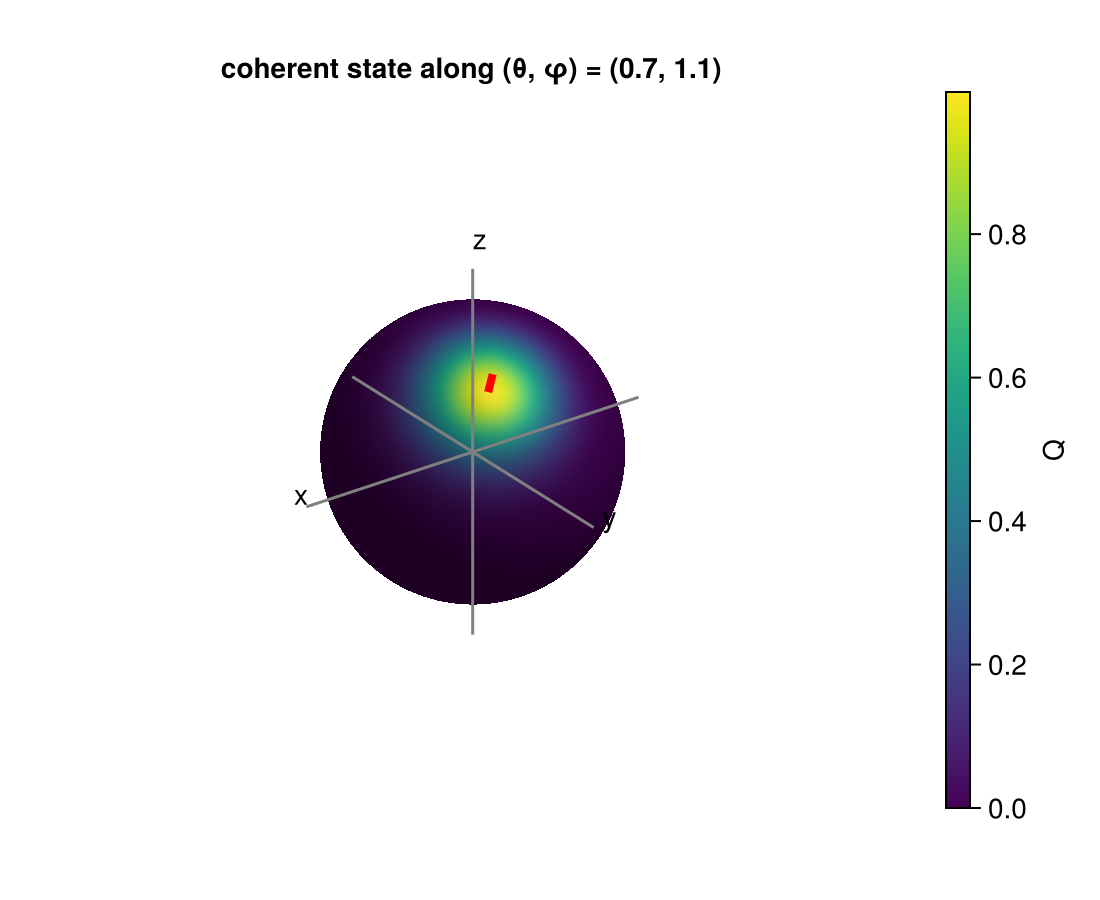

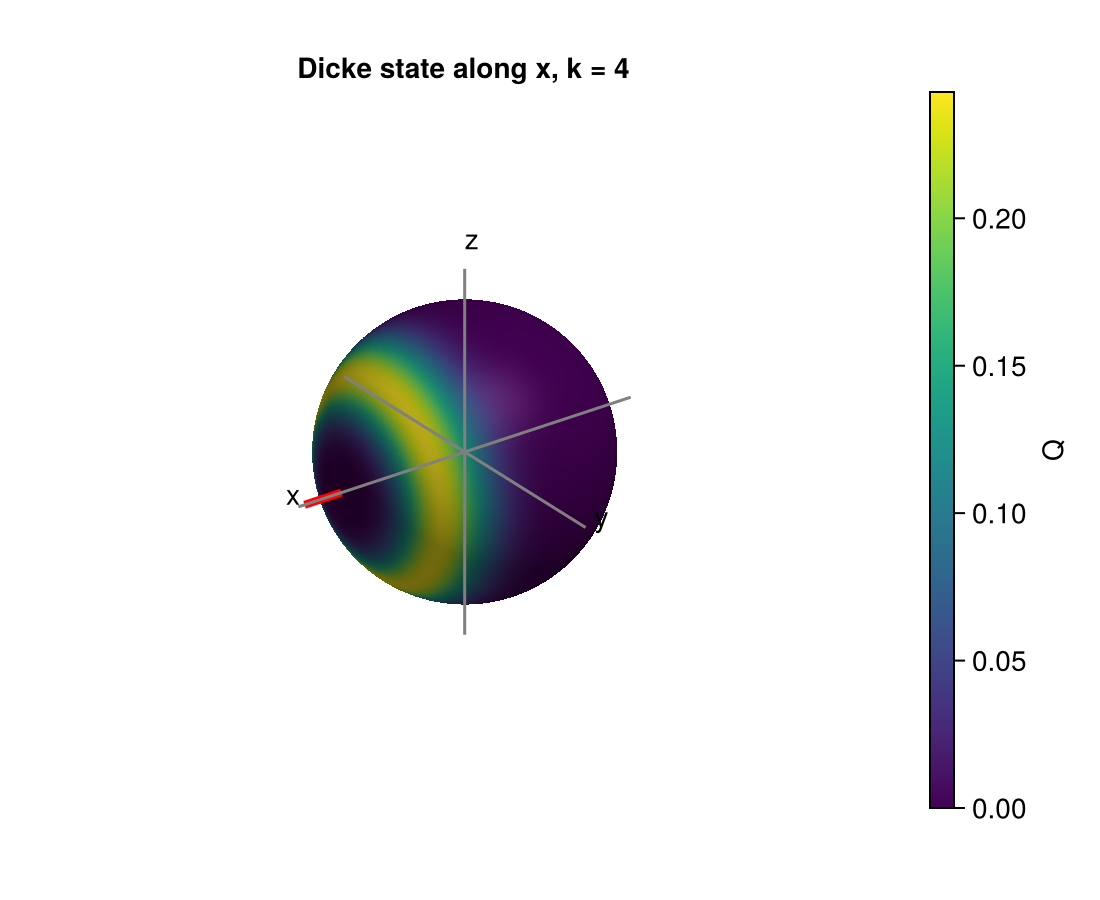

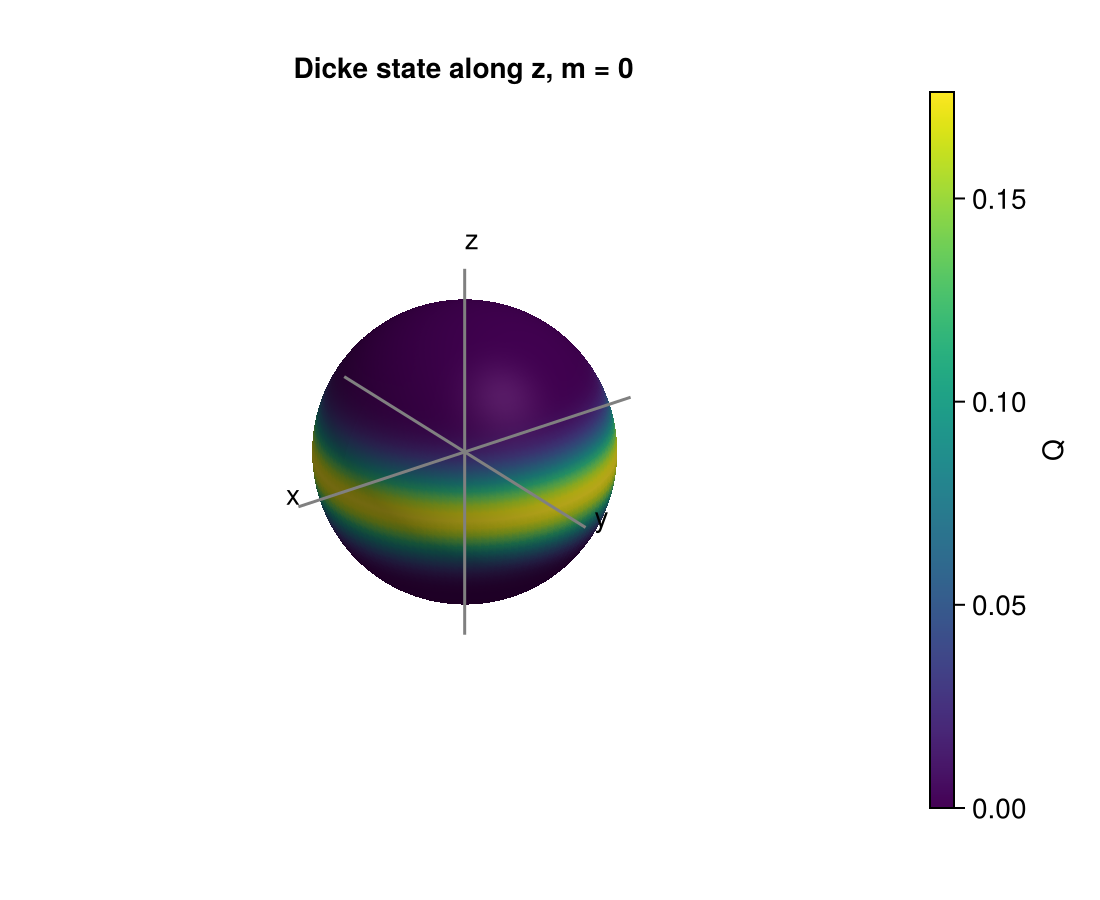

CairoMakie.Screen{IMAGE}


In [12]:
display(bloch_figure(S, init_css(S, 0.7, 1.1); title = "coherent state along (θ, φ) = (0.7, 1.1)"))
display(bloch_figure(S, init_Dickex(S, 4, baseX(S)); title = "Dicke state along x, k = 4"))
display(bloch_figure(S, init_Dickez(S, S + 1); title = "Dicke state along z, m = 0"))

## 4. Dynamics

Each example below follows the same pattern:

1. build $H$ from the library's operators and diagonalise it **once** (`diagonalisation`), or, for a diagonal $H$,
   take its diagonal and use `evol_diag`;
2. compute the state at each time, **starting from the initial state** every time;
3. compute the moments for the curves (`expval`, `variance`), and draw a few times on the sphere (`bloch_row`).

Change the parameters at the top of each cell and rerun it.

### 4.1 Rabi rotation $H = \Omega S_x$
The evolution of 2.6 over two full periods. **Curves:** $\langle S_z\rangle$ and $\mathrm{Var}(S_z)$ lie on top of the
exact formulas $S\cos\Omega t$ and $\tfrac{S}{2}\sin^2\Omega t$.
**Sphere:** the coherent spot of CSS+Z simply turns around the $x$ axis, without changing shape.

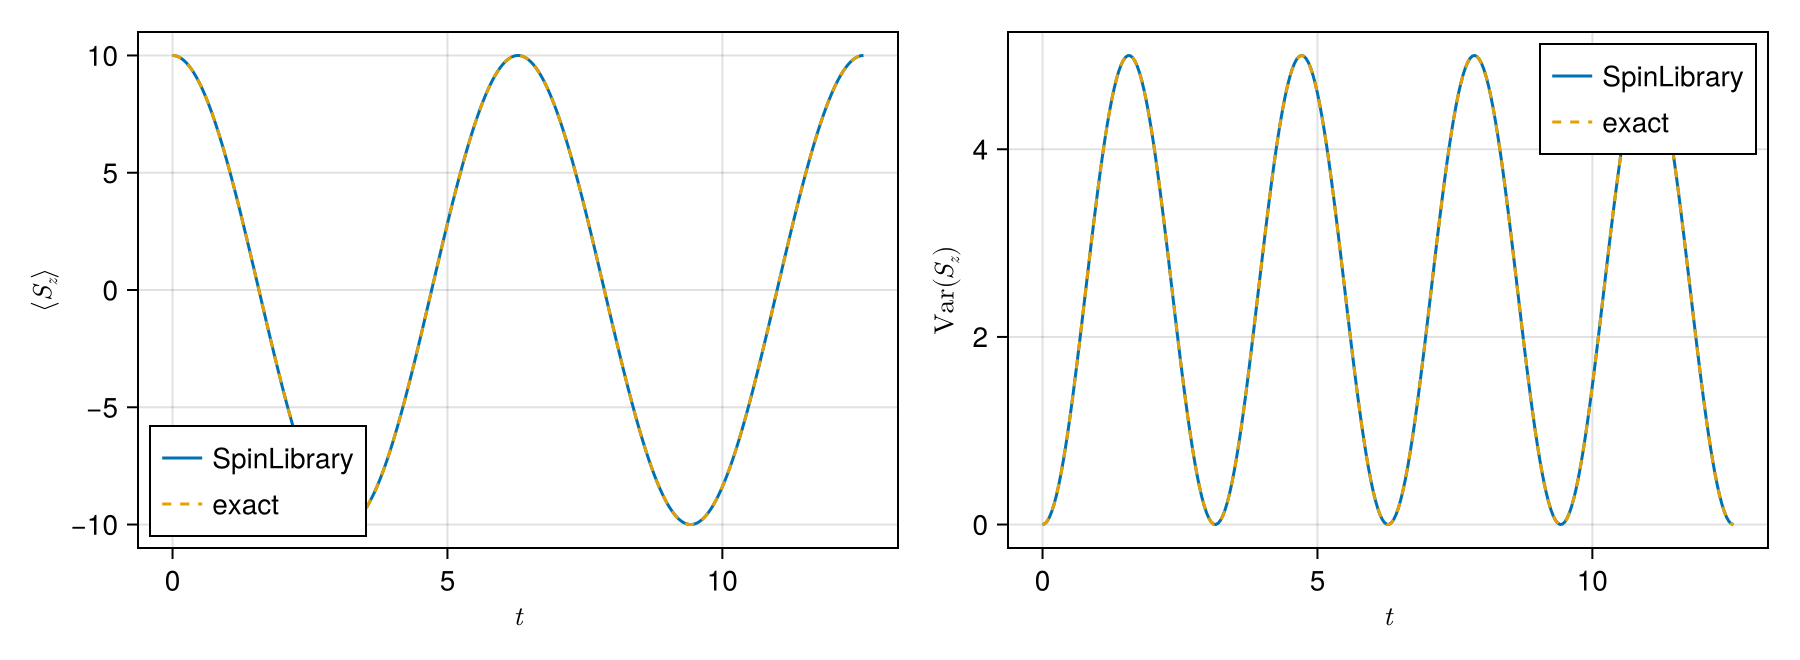

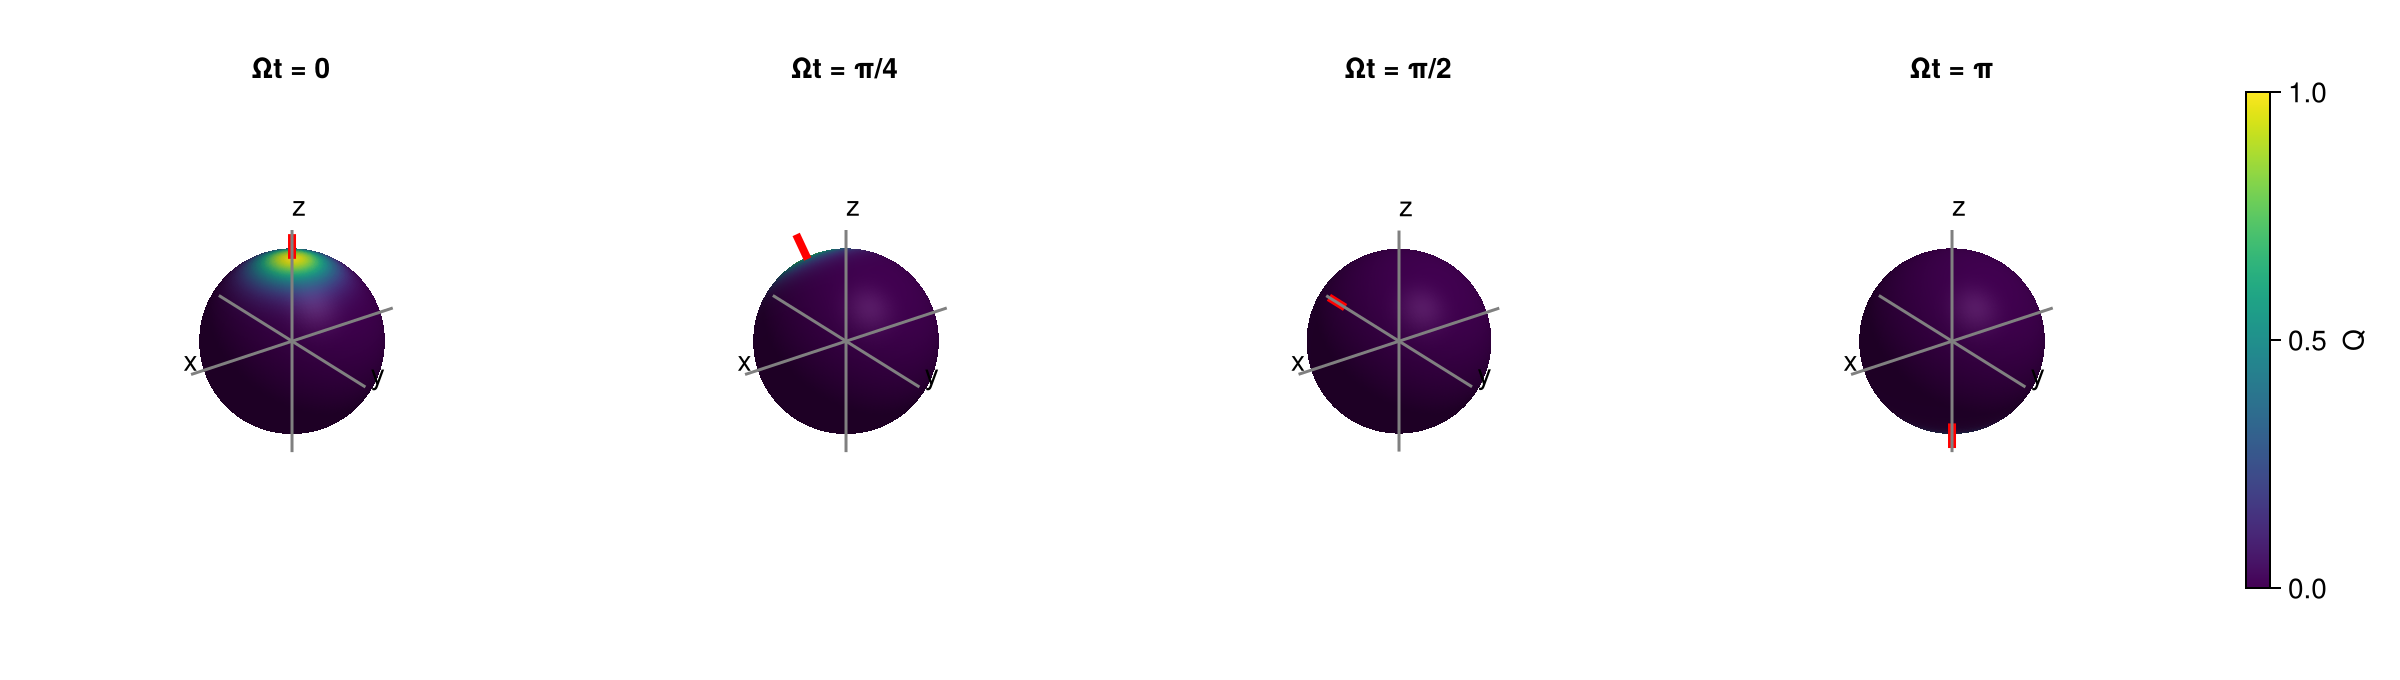

CairoMakie.Screen{IMAGE}


In [13]:
S, Omega = 10, 1.0                                       # parameters: spin length and Rabi frequency
Jx, Jy, Jz = Sx(S), Sy(S), Sz(S)
vp, P, Pm = diagonalisation(Omega * Jx)                  # H = Omega Sx, diagonalised once
psi0 = init_Dickez(S, 1)                                 # CSS+Z

# Curves: mean and variance of S_z, compared with the exact formulas.
times = range(0, 4pi / Omega, length = 300)
states = [evolution(vp, P, Pm, psi0, t) for t in times]
fig = Figure(size = (900, 330))
ax1 = Axis(fig[1, 1]; xlabel = L"t", ylabel = L"\langle S_z \rangle")
ax2 = Axis(fig[1, 2]; xlabel = L"t", ylabel = L"\mathrm{Var}(S_z)")
lines!(ax1, times, [expval(Jz, psi) for psi in states]; label = "SpinLibrary")
lines!(ax1, times, S .* cos.(Omega .* times); linestyle = :dash, label = "exact")
lines!(ax2, times, [variance(Jz, psi) for psi in states]; label = "SpinLibrary")
lines!(ax2, times, S / 2 .* sin.(Omega .* times) .^ 2; linestyle = :dash, label = "exact")
axislegend(ax1, position = :lb); axislegend(ax2, position = :rt)
display(fig)

# Sphere: four times along half a period.
snap = [0, pi/4, pi/2, pi] ./ Omega
display(bloch_row(S, [evolution(vp, P, Pm, psi0, t) for t in snap], ["Ωt = 0", "Ωt = π/4", "Ωt = π/2", "Ωt = π"]))

### 4.2 One-axis twisting $H = S_z^2$
The observables $\langle S_x\rangle$ and $\mathrm{Var}(S_x)$ under
$$|\psi (t)\rangle = e^{-i\hat H t} |\mathrm{CSS}_X\rangle, \qquad \hat H = (\hat{S}^z)^2 .$$

$H$ is diagonal, so `evol_diag` gives the exact state at each time (diagonalising $H$ with `diagonalisation` and
using `evolution` would give the same result, only slower).

**Curves:** $\langle S_x\rangle$ follows the exact $S\cos(t)^{2S-1}$: it collapses, revives with the opposite sign at
$t = \pi$ and comes back at $t = 2\pi$ (the eigenvalues $m^2$ are integers, so the evolution is periodic).
**Sphere:** the spot of CSS+X shears into an ellipse (squeezing), wraps around the equator and, at $t = \pi/2$,
becomes a **cat state**: two opposite spots, along $\pm x$ for this $S$; at $t = \pi$ it is CSS−X.

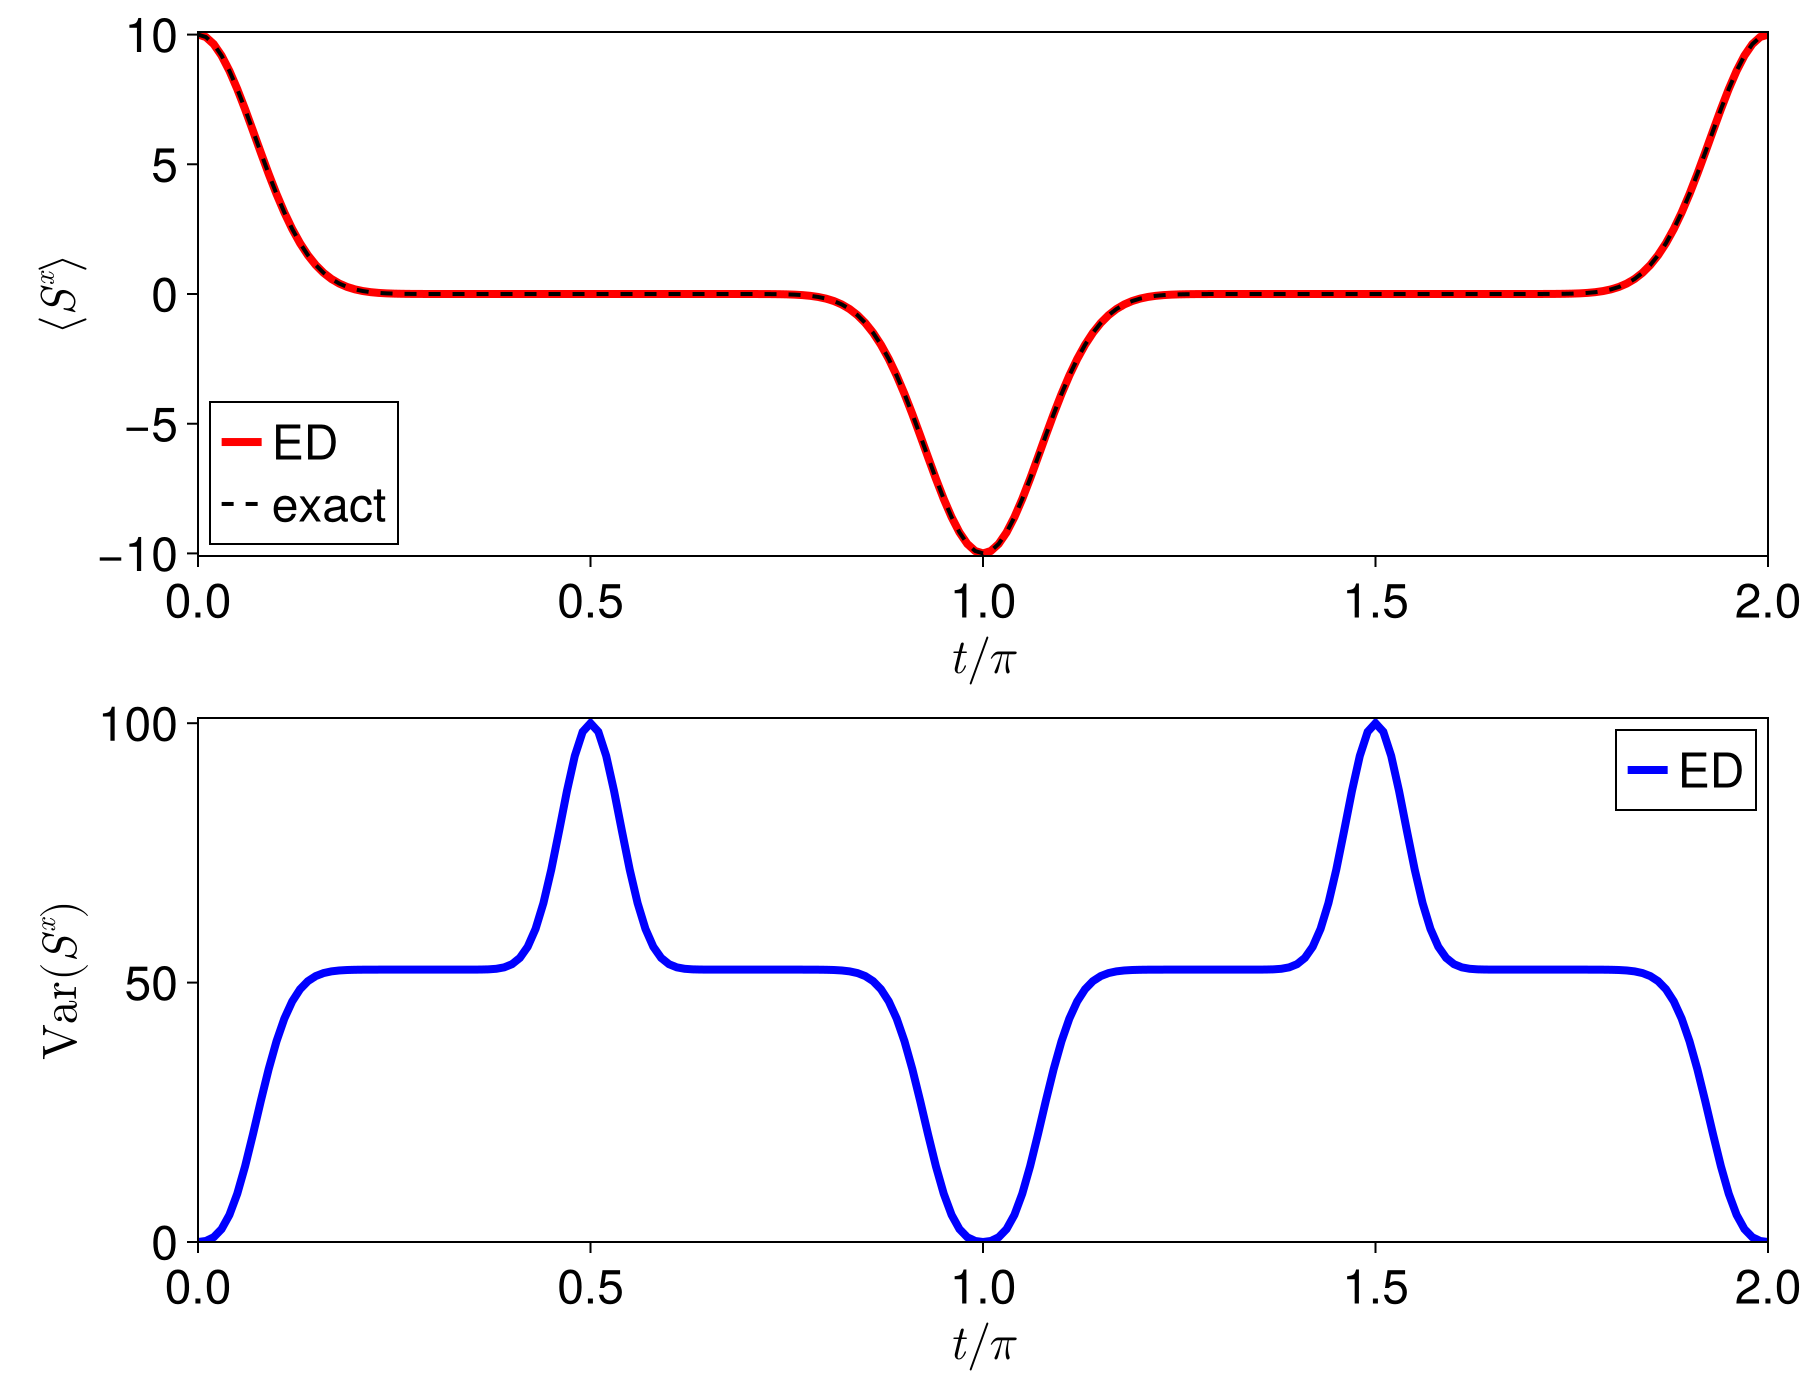

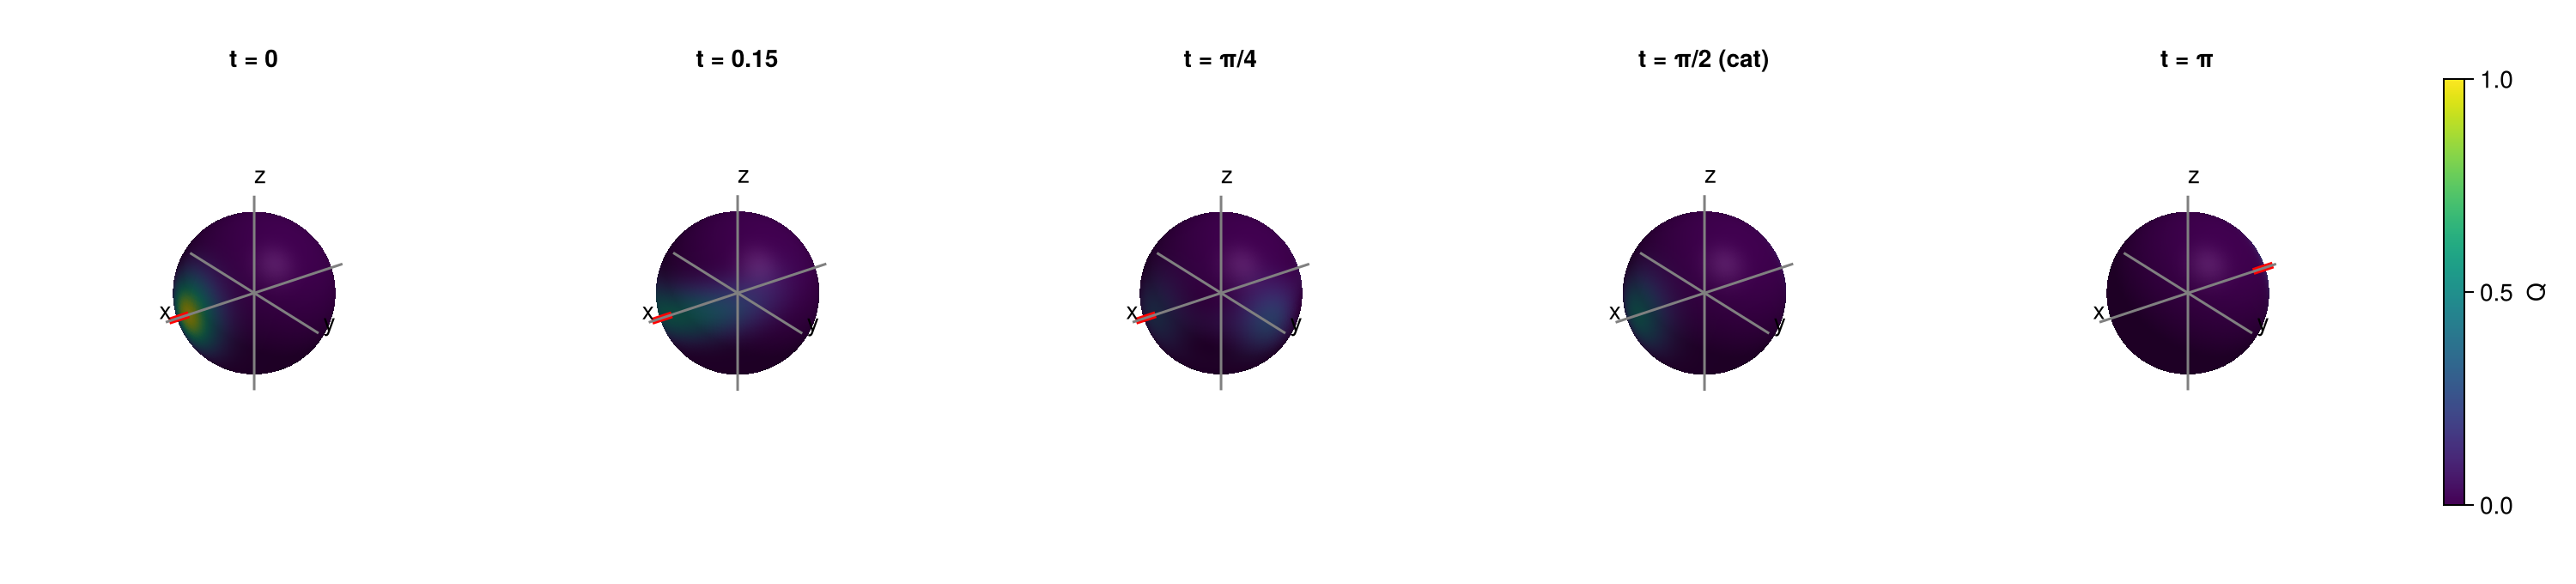

CairoMakie.Screen{IMAGE}


In [14]:
S = 10
Jx = Sx(S)
E_oat = diag(Sz(S) * Sz(S))                     # diagonal of H = Sz^2
init = init_cssX(S)                             # initial state CSS+X

# Mean and variance of Jx along the evolution.
tlen, tmax = 201, 2pi
les_t = range(0, tmax, length = tlen)
MeanX = zeros(tlen)
VarX = zeros(tlen)
for (kt, t) in enumerate(les_t)
    psi_t = evol_diag(E_oat, init, t)
    MeanX[kt] = expval(Jx, psi_t)
    VarX[kt] = variance(Jx, psi_t)
end

# Plot (the commented lines show how to save the data and the figure).
f = Figure(size = (900, 700), fontsize = 24)
ax1 = Axis(f[1, 1]; xlabel = L"t/\pi", ylabel = L"\langle S^{x} \rangle", xgridvisible = false, ygridvisible = false)
ax2 = Axis(f[2, 1]; xlabel = L"t/\pi", ylabel = L"\mathrm{Var} ( S^{x} )", xgridvisible = false, ygridvisible = false)
lines!(ax1, les_t / pi, MeanX; linewidth = 4, color = :red, label = "ED")
lines!(ax1, les_t / pi, S .* cos.(les_t) .^ (2S - 1); linewidth = 2, color = :black, linestyle = :dash, label = "exact")
lines!(ax2, les_t / pi, VarX; linewidth = 4, color = :blue, label = "ED")
axislegend(ax1, position = :lb)
axislegend(ax2, position = :rt)
limits!(ax1, 0, tmax / pi, -S * 1.01, S * 1.01)
limits!(ax2, 0, tmax / pi, 0, S * S * 1.01)
# save_object("evolution_Jx_S$(S).jld2", MeanX); save_object("evolution_VarX_S$(S).jld2", VarX)
# save("evolution_S$(S).png", f)
display(f)

# Sphere: from CSS+X to the cat state and to CSS-X.
snap = [0, 0.15, pi/4, pi/2, pi]
display(bloch_row(S, [evol_diag(E_oat, init, t) for t in snap], ["t = 0", "t = 0.15", "t = π/4", "t = π/2 (cat)", "t = π"]))

### 4.3 Twisting and turning $H = \chi S_z^2 + \Omega S_x$
A genuinely non-diagonal Hamiltonian with no simple closed form: the twisting term $\chi S_z^2$ shears the
fluctuations, the transverse field $\Omega S_x$ rotates them.

Starting from CSS+X, the mean spin stays along $x$ (both $H$ and the initial state are symmetric under a
$\pi$ rotation about $x$), while the fluctuations in the $y$–$z$ plane are reshaped. To quantify this:

* $\mathrm{Var}_{\min}$: the **smallest variance in the $y$–$z$ plane**, i.e. of $S_y\cos\alpha + S_z\sin\alpha$
  minimised over $\alpha$: the smallest eigenvalue of the $2\times2$ covariance matrix of $(S_y, S_z)$;
* the **Wineland squeezing parameter** $\xi^2 = 2S\,\mathrm{Var}_{\min}/\langle S_x\rangle^2$, which is $1$ for a
  coherent state; $\xi^2 < 1$ means **spin squeezing** (improved precision in Ramsey interferometry).

**Sphere:** the state is squeezed quickly (the minimum of $\xi^2$), and then spreads over the sphere.
Try changing $\chi$ and $\Omega$: for $\Omega = 0$ you get back pure one-axis twisting.

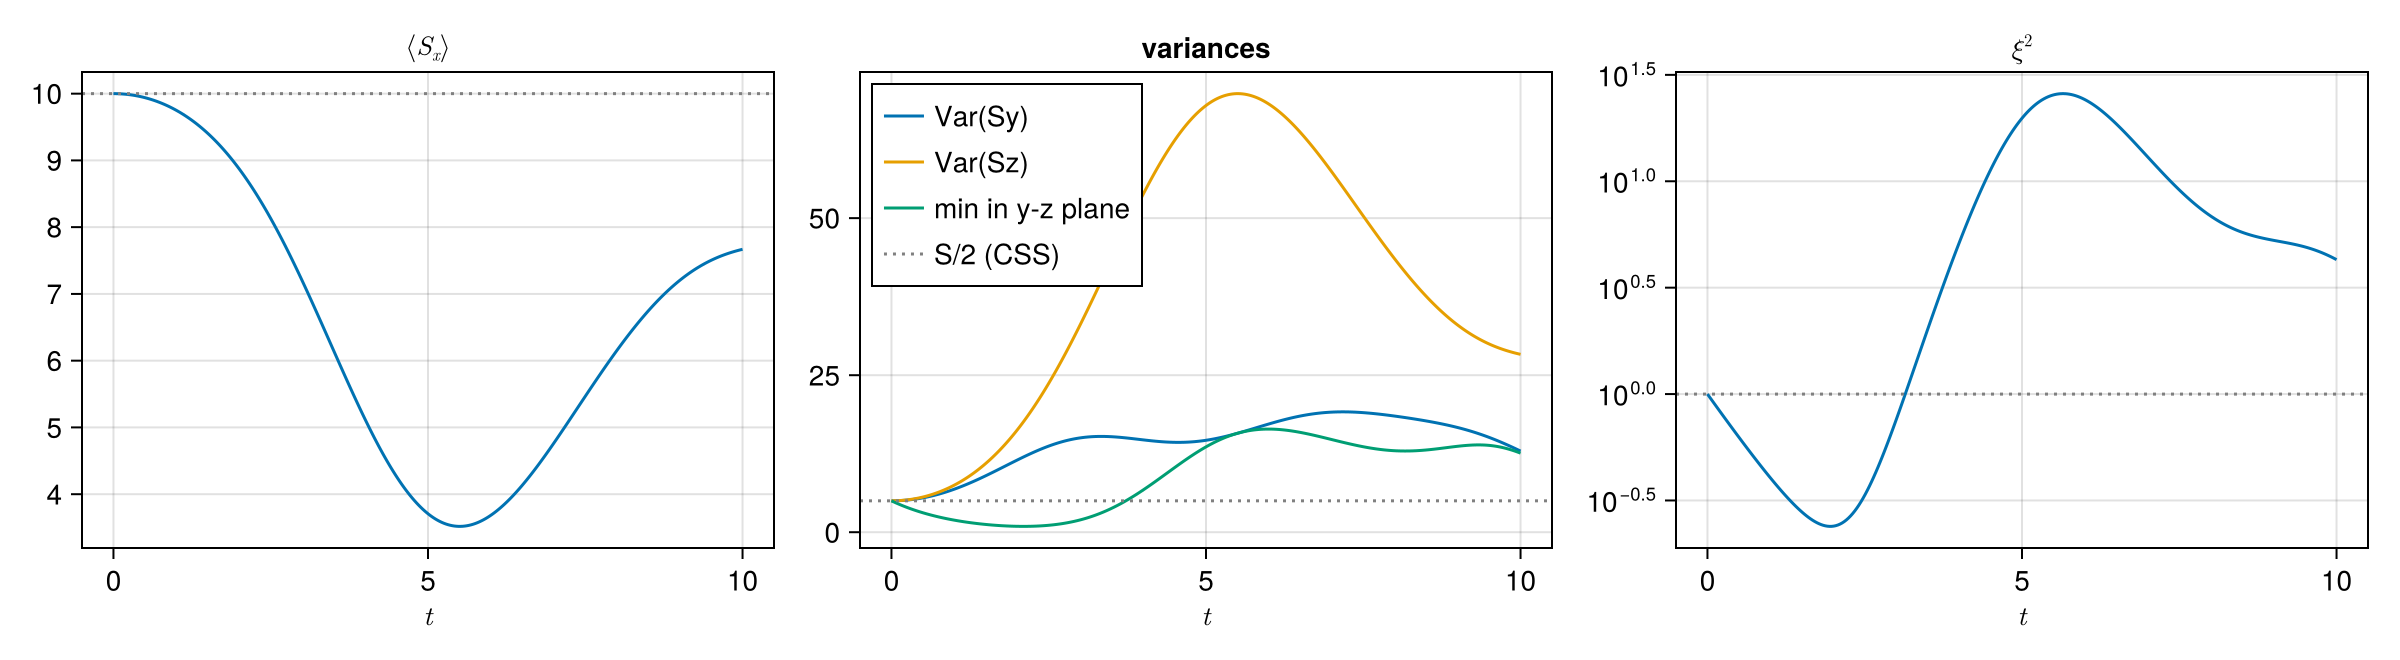

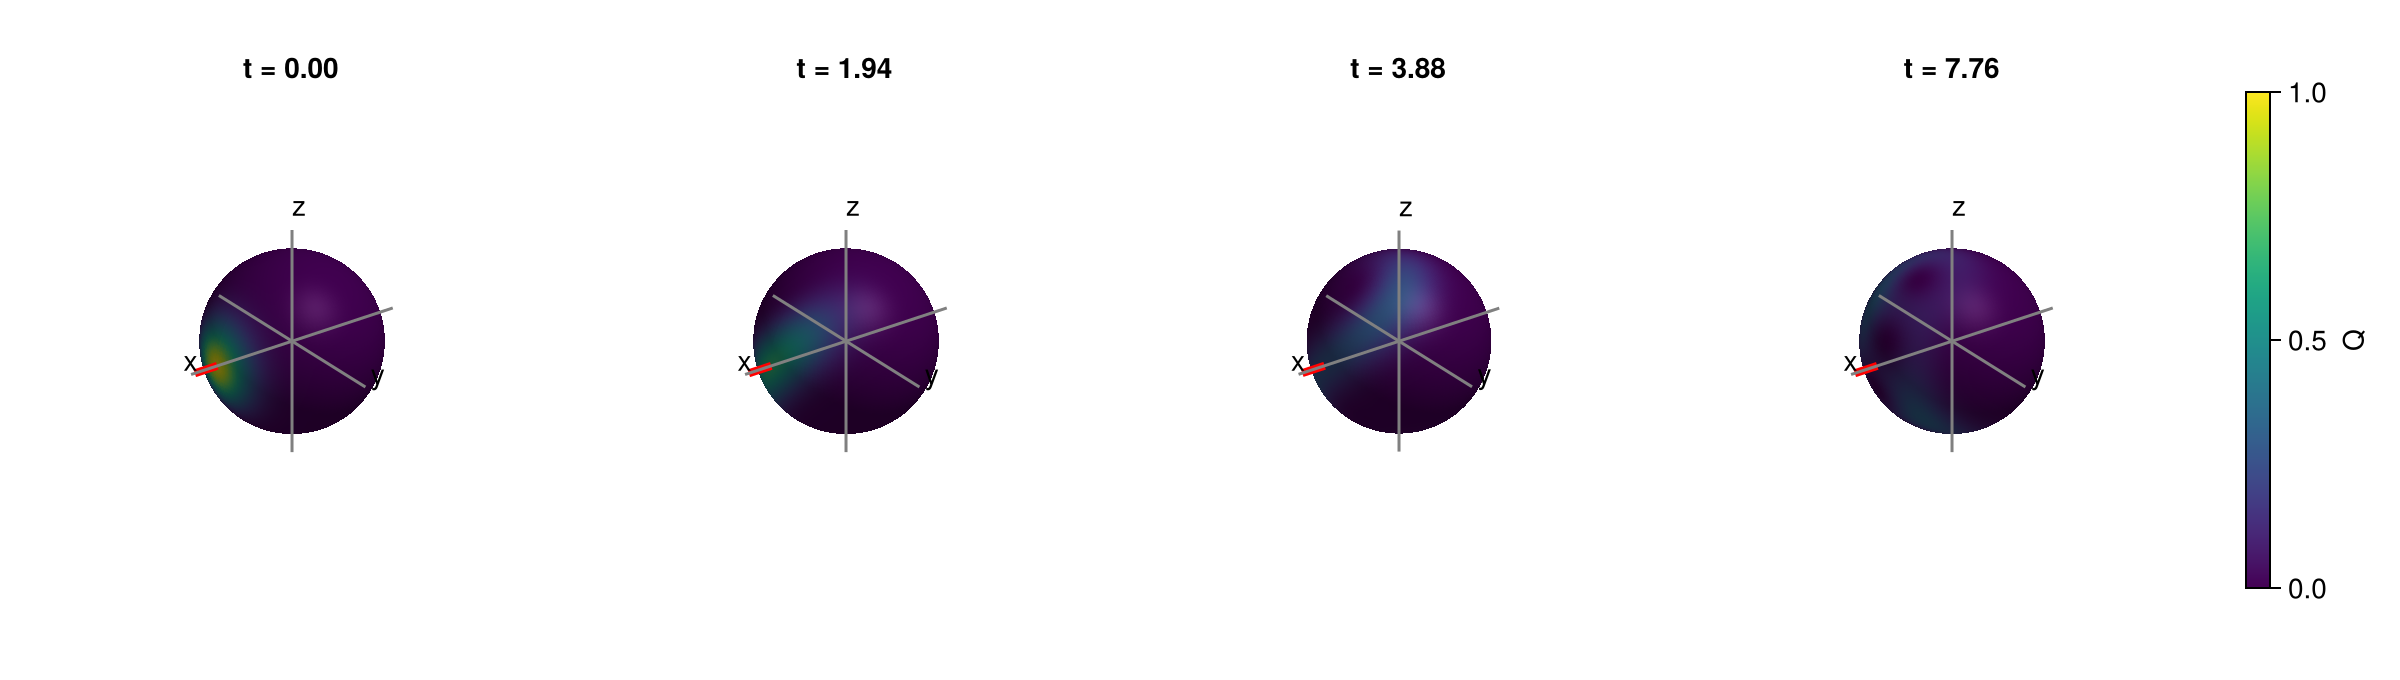

best squeezing: xi^2 = 0.2390 at t = 1.940


CairoMakie.Screen{IMAGE}


In [15]:
S, chi, Omega, tmax = 10, 0.05, 0.5, 10.0                # parameters
Jx, Jy, Jz = Sx(S), Sy(S), Sz(S)
vp, P, Pm = diagonalisation(chi * Jz * Jz + Omega * Jx)  # diagonalised once
psi0 = init_cssX(S)

function min_transverse_variance(psi)
    # Smallest eigenvalue of C = [Var Sy  Cov; Cov  Var Sz],  Cov = Re<(Sy Sz + Sz Sy)/2> - <Sy><Sz>.
    y, z = expval(Jy, psi), expval(Jz, psi)
    cov = expval((Jy * Jz + Jz * Jy) / 2, psi) - y * z
    C = [variance(Jy, psi) cov; cov variance(Jz, psi)]
    return eigmin(Symmetric(C))
end

# Curves.
times = range(0, tmax, length = 300)
states = [evolution(vp, P, Pm, psi0, t) for t in times]
meanx = [expval(Jx, psi) for psi in states]
vmin = [min_transverse_variance(psi) for psi in states]
xi2 = 2S .* vmin ./ meanx .^ 2

fig = Figure(size = (1200, 330))
ax1 = Axis(fig[1, 1]; xlabel = L"t", title = L"\langle S_x \rangle")
ax2 = Axis(fig[1, 2]; xlabel = L"t", title = "variances")
ax3 = Axis(fig[1, 3]; xlabel = L"t", title = L"\xi^2", yscale = log10)
lines!(ax1, times, meanx); hlines!(ax1, [S]; color = :gray, linestyle = :dot)
lines!(ax2, times, [variance(Jy, psi) for psi in states]; label = "Var(Sy)")
lines!(ax2, times, [variance(Jz, psi) for psi in states]; label = "Var(Sz)")
lines!(ax2, times, vmin; label = "min in y-z plane")
hlines!(ax2, [S / 2]; color = :gray, linestyle = :dot, label = "S/2 (CSS)")
lines!(ax3, times, xi2); hlines!(ax3, [1]; color = :gray, linestyle = :dot)
axislegend(ax2, position = :lt)
display(fig)
best = argmin(xi2)
@printf("best squeezing: xi^2 = %.4f at t = %.3f\n", xi2[best], times[best])

# Sphere: before, at and after the best squeezing.
snap = [0, times[best], 2 * times[best], 4 * times[best]]
display(bloch_row(S, [evolution(vp, P, Pm, psi0, t) for t in snap], [@sprintf("t = %.2f", t) for t in snap]))

### 4.4 Ramsey interferometry
The basic sequence of atomic clocks and interferometers:

1. a $\pi/2$ pulse about $y$ turns the spin from $+z$ to the equator ($+x$),
2. during a free evolution time $T$ with detuning $\delta$ the spin precesses about $z$ by the angle $\delta T$
   (the diagonal evolution under $S_z$ for a time $\delta T$),
3. a second $\pi/2$ pulse about $y$ maps that angle back onto $S_z$.

**Curve:** the final population imbalance is $\langle S_z\rangle = -S\cos(\delta T)$, the **Ramsey fringes**.
**Sphere:** the state after each step, for one detuning.

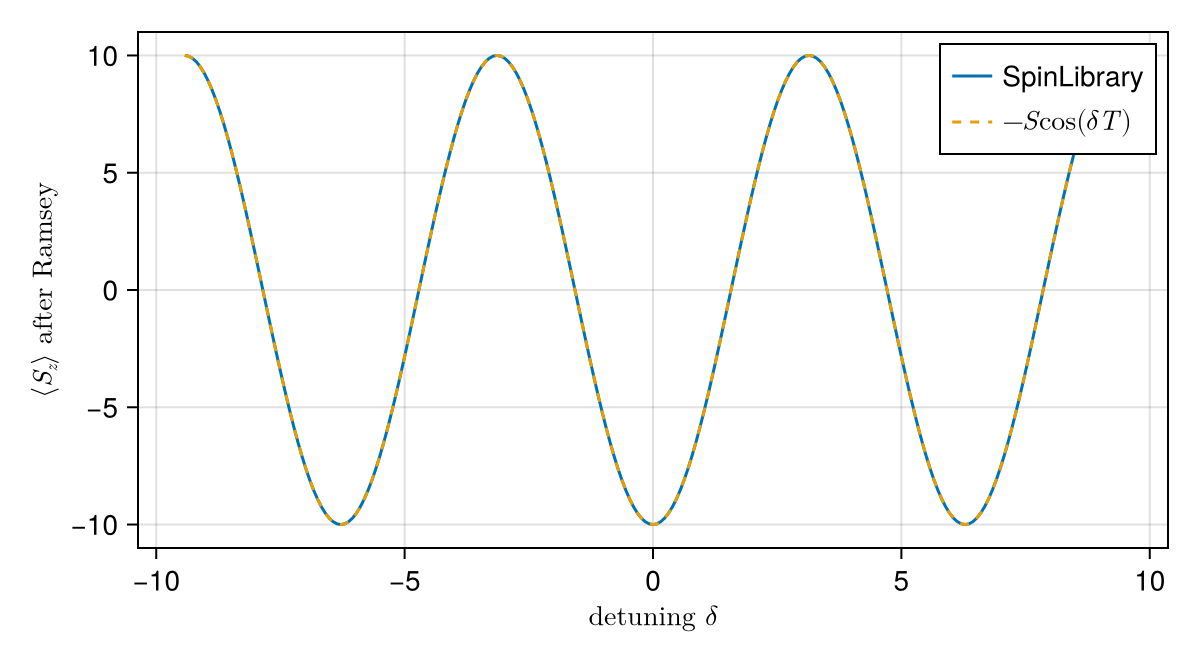

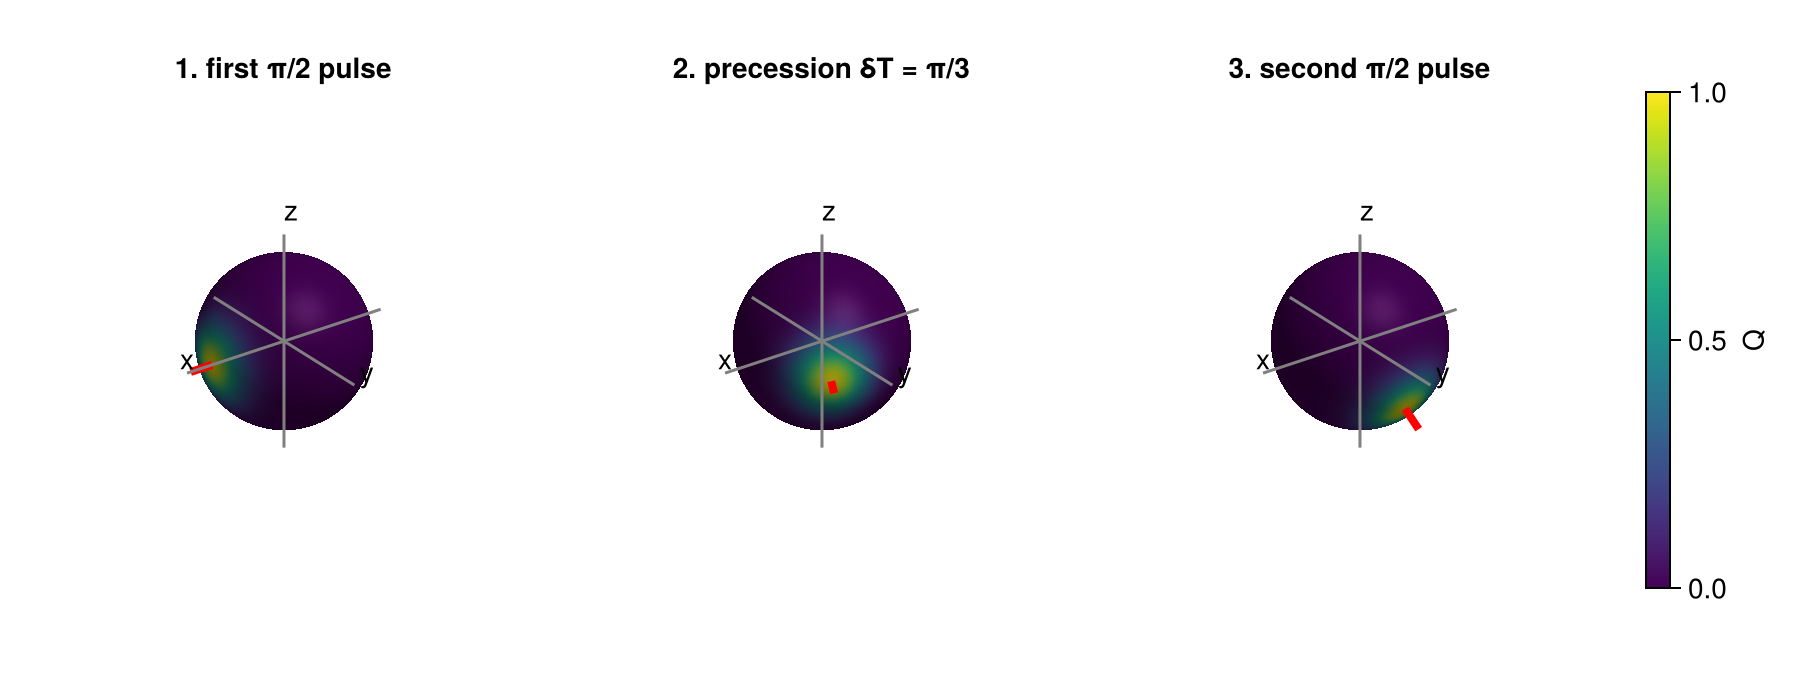

CairoMakie.Screen{IMAGE}


In [16]:
S, T = 10, 1.0                                           # parameters: spin length and free evolution time
Ry = diagonalisation(Sy(S))                              # for the pi/2 pulses about y (diagonalised once)
Ez = diag(Sz(S))                                         # precession about z: diagonal evolution under Sz
ramsey(delta) = evolution(Ry..., evol_diag(Ez, evolution(Ry..., init_Dickez(S, 1), pi/2), delta * T), pi/2)

# Curve: <Sz> after the sequence, for many detunings.
deltas = range(-3pi, 3pi, length = 241)
fig = Figure(size = (600, 330))
ax = Axis(fig[1, 1]; xlabel = L"\textrm{detuning } \delta", ylabel = L"\langle S_z \rangle \textrm{ after Ramsey}")
lines!(ax, deltas, [expval(Sz(S), ramsey(d)) for d in deltas]; label = "SpinLibrary")
lines!(ax, deltas, -S .* cos.(deltas .* T); linestyle = :dash, label = L"-S\cos(\delta T)")
axislegend(ax, position = :rt)
display(fig)

# Sphere: the three steps of the sequence for delta T = pi/3.
delta = pi / 3
step1 = evolution(Ry..., init_Dickez(S, 1), pi/2)
step2 = evol_diag(Ez, step1, delta * T)
step3 = evolution(Ry..., step2, pi/2)
display(bloch_row(S, [step1, step2, step3], ["1. first π/2 pulse", "2. precession δT = π/3", "3. second π/2 pulse"]))